In [1]:
### PHASE 1 exercices & training

import numpy as np

rng = np.random.default_rng(42)
n = 200

x = 2 * rng.random((n, 1))                    # feature brute, forme (n, 1)
y = 4 + 3 * x[:, 0] + rng.normal(0, 1, n)     # cible, forme (n,)

X = np.c_[np.ones((n, 1)), x]                 # matrice de design avec x0 = 1, forme (n, 2)

print(X.shape, y.shape)

(200, 2) (200,)


In [4]:
def equation_normale(X, y):
    theta = np.linalg.solve(X.T@X, X.T@y)
    return(theta)

[3.69084138 3.32960458]


In [6]:
def gradient_batch(X, y, alpha=1.2, n_iter=1000):
    n, d = X.shape
    theta = np.zeros(d)
    historique = []

    for k in range(n_iter):
        residu = X @ theta - y                   # erreurs de prédiction, forme (n,)
        gradient = (1/n) * X.T @ residu          # forme (d,)
        theta = theta - alpha * gradient         # un pas de descente
        historique.append((1/(2*n)) * residu @ residu)

    return theta, historique

theta_gd, hist = gradient_batch(X, y)
print(theta_gd)
print(np.abs(theta_gd - theta_ne).max())
print(hist[0], hist[10], hist[-1])

[-3.13290648e+197 -3.63154440e+197]
3.631544404022074e+197
26.613777633812887 227086.07099382157 inf


C:\Users\Utilisateur\AppData\Local\Temp\ipykernel_29496\709471004.py:10: RuntimeWarning: overflow encountered in matmul
  historique.append((1/(2*n)) * residu @ residu)


In [7]:
def sgd(X, y, alpha=0.01, n_epoques=50, graine=0):
    rng = np.random.default_rng(graine)
    n, d = X.shape
    theta = np.zeros(d)
    historique = []

    for epoque in range(n_epoques):
        for i in rng.permutation(n):
            xi = X[i]                          # une ligne de X, forme (d,) = (2,)
            yi = y[i]                          # un nombre
            erreur = xi @ theta - yi           # h_theta(xi) - yi, un nombre
            gradient = erreur * xi             # forme (2,), comme theta
            theta = theta - alpha * gradient   # règle LMS
        residu = X @ theta - y
        historique.append((1/(2*n)) * residu @ residu)

    return theta, historique

theta_sgd, hist_sgd = sgd(X, y)
print(theta_sgd)
print(np.abs(theta_sgd - theta_ne).max())
print(hist_sgd[0], hist_sgd[-1])

[3.686801   3.33184665]
0.004040383569574146
0.5207330553161901 0.49790673940388985


In [8]:
from sklearn.linear_model import LinearRegression

modele = LinearRegression()
modele.fit(x, y)                                   # x brut, sans la colonne de 1
theta_sk = np.r_[modele.intercept_, modele.coef_]

print("sklearn         :", theta_sk)
print("équation normale:", np.allclose(theta_ne,  theta_sk, atol=1e-6, rtol=0))
print("GD batch        :", np.allclose(theta_gd,  theta_sk, atol=1e-6, rtol=0))
print("SGD             :", np.allclose(theta_sgd, theta_sk, atol=1e-6, rtol=0))

sklearn         : [3.69084138 3.32960458]
équation normale: True
GD batch        : False
SGD             : False


In [11]:
print(theta_gd)
theta_gd, hist = gradient_batch(X, y, alpha=0.1, n_iter=1000)
print("GD batch        :", np.allclose(theta_gd, theta_sk, atol=1e-6, rtol=0))

[-3.13290648e+197 -3.63154440e+197]
GD batch        : True


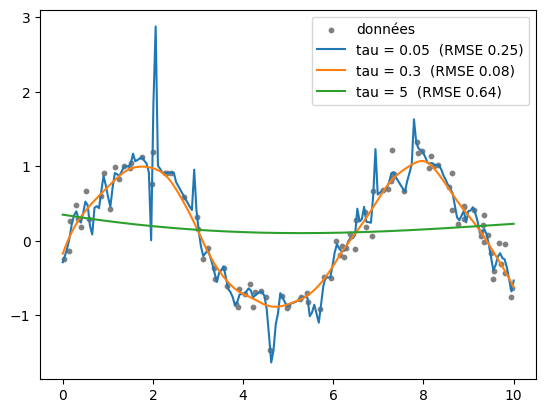

In [12]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
n = 100
x = np.sort(rng.uniform(0, 10, n))
y = np.sin(x) + rng.normal(0, 0.2, n)
X = np.c_[np.ones(n), x]

def lwr_predict(x_query, X, y, tau):
    w = np.exp(-(X[:, 1] - x_query)**2 / (2 * tau**2))  # un poids par exemple, forme (n,)
    XtW = X.T * w                                       # équivaut à X.T @ diag(w), sans construire la matrice n×n
    theta = np.linalg.solve(XtW @ X, XtW @ y)           # θ = (XᵀWX)⁻¹ XᵀWy
    return np.array([1, x_query]) @ theta

x_test = np.linspace(0, 10, 200)
y_vrai = np.sin(x_test)

plt.scatter(x, y, s=10, color="gray", label="données")
for tau in [0.05, 0.3, 5]:
    pred = np.array([lwr_predict(q, X, y, tau) for q in x_test])
    rmse = np.sqrt(np.mean((pred - y_vrai)**2))
    plt.plot(x_test, pred, label=f"tau = {tau}  (RMSE {rmse:.2f})")
plt.legend()
plt.show()

In [1]:
## Essais HOML

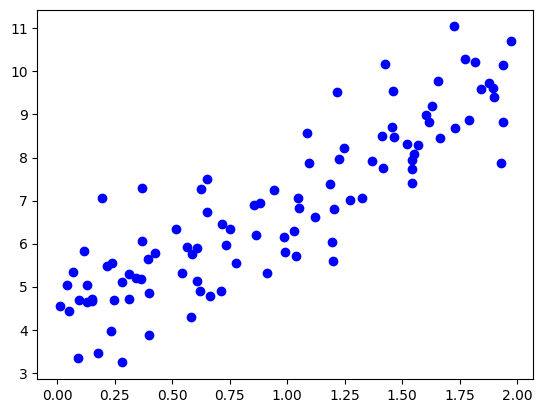

In [8]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(42)
n = 100
X = 2*np.random.rand(n,1)
y = 4+3*X+np.random.randn(n,1)
plt.scatter(X,y, c='b')

In [9]:
from sklearn.preprocessing import add_dummy_feature

In [10]:
X_b = add_dummy_feature(X)
theta_best=np.linalg.inv(X_b.T@X_b)@X_b.T@y

In [11]:
theta_best

array([[4.21509616],
       [2.77011339]])

In [12]:
X_new = np.array([[0], [2]])

In [13]:
X_new_b=add_dummy_feature(X_new)
y_predict=X_new_b@theta_best
y_predict

array([[4.21509616],
       [9.75532293]])

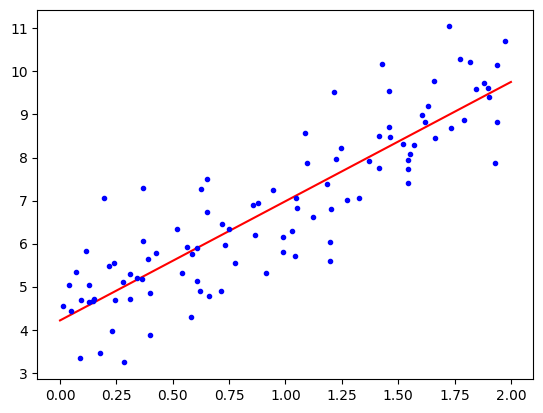

In [14]:
import matplotlib.pyplot as plt
plt.plot(X_new, y_predict, "r-", label="Predictions")
plt.plot(X, y, "b.")

plt.show()